##Theoretical

Q1. What is a Support Vector Machine (SVM)?

Ans.A Support Vector Machine (SVM) is a supervised machine learning algorithm used for classification and regression. It finds an optimal hyperplane that separates data points into different classes while maximizing the margin between them.

Q2. What is the difference between Hard Margin and Soft Margin SVM?

Ans.Hard Margin SVM: Assumes data is strictly linearly separable with zero tolerance for misclassifications, making it highly sensitive to outliers.

Soft Margin SVM: Allows a controlled number of misclassifications by introducing a slack variable, making it robust to noise and overlapping data.

Q3. What is the mathematical intuition behind SVM?

Ans.The intuition is to maximize the geometric margin $\frac{2}{\Vert{}w\Vert{}}$ subject to the constraint that all points are correctly classified ($y_i(w \cdot x_i + b) \ge 1$). Solving this optimization finds the weight vector $w$ and bias $b$.

Q4. What is the role of Lagrange Multipliers in SVM?

Ans.Lagrange multipliers convert the constrained optimization problem of maximizing margins into an unconstrained dual Lagrangian form. This allows the model to handle inequalities and enables the use of the kernel trick via inner products.

Q5. What are Support Vectors in SVM?

Ans.Support vectors are the data points lying closest to the decision boundary (hyperplane). They exclusively determine the position and orientation of the optimal hyperplane; removing other points has no effect on the model.

Q6. What is a Support Vector Classifier (SVC)?

Ans.SVC is the classification variant of SVM. It separates categorical data classes by finding an optimal decision boundary or hyperplane that maximizes the margin between them.

Q7. What is a Support Vector Regressor (SVR)?

Ans.SVR is the regression variant of SVM. Instead of separating classes, it fits a continuous function within a threshold ($\epsilon$-insensitive tube) around the target values, keeping as many points as possible inside the margin.

Q8. What is the Kernel Trick in SVM?

Ans.The kernel trick implicitly maps low-dimensional non-linear data into a higher-dimensional space without explicitly computing the coordinates, using kernel functions to calculate inner products efficiently.

Q9. Compare Linear Kernel, Polynomial Kernel, and RBF Kernel?

Ans.Linear Kernel: Best for linearly separable and high-dimensional sparse data.

Polynomial Kernel: Captures feature interactions up to a specified degree.

RBF Kernel: Maps data into infinite dimensions, highly flexible for complex non-linear boundaries.

Q10. What is the effect of the C parameter in SVM?

Ans.High C: Low training error, narrower margin, strict penalty for misclassifications (risk of overfitting).

Low C: Wider margin, allows some misclassifications, smoother boundary (reduces overfitting).

Q11. What is the role of the Gamma parameter in RBF Kernel SVM?

Ans.High Gamma: Creates a tight, localized influence radius around data points, leading to complex boundaries and potential overfitting.

High Gamma / Low Gamma: Broad influence area, leading to smoother boundaries and potential underfitting.

Q12. What is the Naïve Bayes classifier, and why is it called "Naïve"?

Ans.Naïve Bayes is a probabilistic classifier based on Bayes' Theorem. It is called "naïve" because it assumes all features are conditionally independent given the class label, a rare occurrence in real-world data.

Q13. What is Bayes' Theorem?

Ans.Bayes' Theorem calculates the posterior probability of an event based on prior knowledge:$$P(A\vert{}B) = \frac{P(B\vert{}A)P(A)}{P(B)}$$where $P(A\vert{}B)$ is the posterior, $P(B\vert{}A)$ is the likelihood, $P(A)$ is the prior, and $P(B)$ is the evidence.

Q14. Explain the differences between Gaussian Naïve Bayes, Multinomial Naïve Bayes, and Bernoulli Naïve Bayes?

Ans.Gaussian NB: Assumes continuous features follow a normal distribution.

Multinomial NB: Designed for discrete count data (e.g., word counts in text).

Bernoulli NB: Designed for binary/boolean features (e.g., word presence/absence).

Q15. When should you use Gaussian Naïve Bayes over other variants?

Ans.You should use Gaussian Naïve Bayes when your dataset consists of continuous, real-valued features that can be modeled reasonably well using a normal (Gaussian) distribution.

Q16. What are the key assumptions made by Naïve Bayes?

Ans.Conditional Independence: All features are independent of each other given the target class label.

Feature Equal Importance: Every feature contributes equally to the outcome.

Q17. What are the advantages and disadvantages of Naïve Bayes?

Ans.Advantages: Fast training/prediction, highly scalable, handles high-dimensional text data well, requires less training data.

Disadvantages: The conditional independence assumption is often violated, degrading performance when features are heavily correlated.

Q18. Why is Naïve Bayes a good choice for text classification?

Ans.Text data features high dimensionality and sparsity (e.g., vocabulary counts). Naïve Bayes handles high-dimensional sparse inputs efficiently, computes quickly, and performs remarkably well for spam filtering and sentiment analysis.

Q19. Compare SVM and Naïve Bayes for classification tasks.

Ans.SVM: Maximizes margins, handles feature correlation effectively, uses kernels for non-linear boundaries, but is computationally heavier on large datasets.

Naïve Bayes: Probabilistic, assumes feature independence, extremely fast, highly scalable, but vulnerable to strong feature correlations.

Q20. How does Laplace Smoothing help in Naïve Bayes?   

Ans.Laplace smoothing adds a small constant (usually 1) to probability calculations. This prevents zero-probability errors when a feature value never appears alongside a class label in the training set.

##Practical

In [1]:
#Q21. Write a Python program to train an SVM Classifier on the Iris dataset and evaluate accuracy?
#Ans.
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
X, y = load_iris(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)
model = SVC().fit(X_train, y_train)
print(accuracy_score(y_test, model.predict(X_test)))

0.9333333333333333


In [2]:
#Q22. Write a Python program to train two SVM classifiers with Linear and RBF kernels on the Wine dataset, then compare their accuracies?
#Ans.
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
X, y = load_wine(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)
linear_model = SVC(kernel='linear').fit(X_train, y_train)
rbf_model = SVC(kernel='rbf').fit(X_train, y_train)
print(accuracy_score(y_test, linear_model.predict(X_test)), accuracy_score(y_test, rbf_model.predict(X_test)))

0.9166666666666666 0.6944444444444444


In [3]:
#Q23. Write a Python program to train an SVM Regressor (SVR) on a housing dataset and evaluate it using Mean Squared Error (MSE)?
#Ans.
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error
X, y = fetch_california_housing(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(X[:500], y[:500], test_size=0.2)
model = SVR().fit(X_train, y_train)
print(mean_squared_error(y_test, model.predict(X_test)))

1.2698651383421709


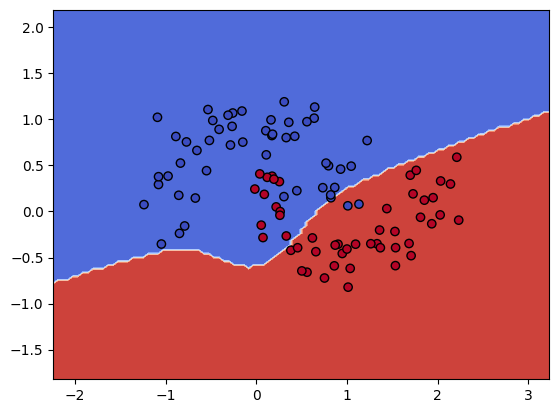

In [4]:
#Q24. Write a Python program to train an SVM Classifier with a Polynomial Kernel and visualize the decision boundary?
#Ans.
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.svm import SVC
from sklearn.inspection import DecisionBoundaryDisplay
X, y = make_moons(n_samples=100, noise=0.2)
model = SVC(kernel='poly', degree=3).fit(X, y)
DecisionBoundaryDisplay.from_estimator(model, X, response_method="predict", cmap=plt.cm.coolwarm)
plt.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.coolwarm, edgecolors='k')
plt.show()

In [5]:
#Q25. Write a Python program to train a Gaussian Naïve Bayes classifier on the Breast Cancer dataset and evaluate accuracy?
#Ans.
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score
X, y = load_breast_cancer(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)
model = GaussianNB().fit(X_train, y_train)
print(accuracy_score(y_test, model.predict(X_test)))

0.9385964912280702


In [6]:
#Q26. Write a Python program to train a Multinomial Naïve Bayes classifier for text classification using the 20 Newsgroups dataset?
#Ans.
from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score
data = fetch_20newsgroups(subset='all', categories=['alt.atheism', 'soc.religion.christian'])
X_vec = CountVectorizer().fit_transform(data.data)
model = MultinomialNB().fit(X_vec, data.target)
print(accuracy_score(data.target, model.predict(X_vec)))

0.9955456570155902


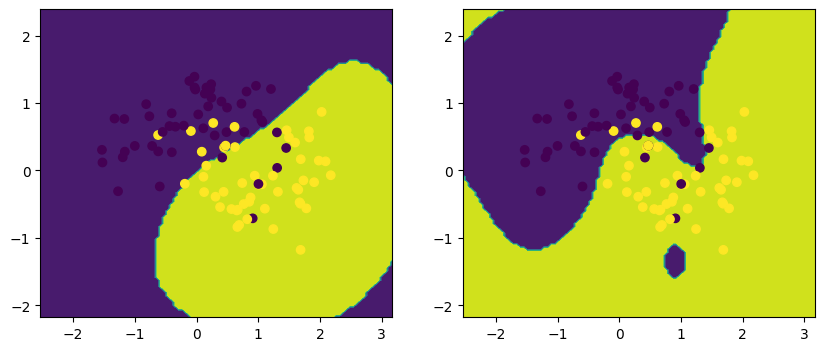

In [7]:
#Q27. Write a Python program to train an SVM Classifier with different C values and compare the decision boundaries visually?
#Ans.
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.svm import SVC
from sklearn.inspection import DecisionBoundaryDisplay
X, y = make_moons(n_samples=100, noise=0.3)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, c in zip(axes, [0.01, 100.0]):
    m = SVC(C=c).fit(X, y)
    DecisionBoundaryDisplay.from_estimator(m, X, response_method="predict", ax=ax)
    ax.scatter(X[:, 0], X[:, 1], c=y)
plt.show()

In [8]:
#Q28. Write a Python program to train a Bernoulli Naïve Bayes classifier for binary classification on a dataset with binary features?
#Ans.
import numpy as np
from sklearn.naive_bayes import BernoulliNB
from sklearn.metrics import accuracy_score
X = np.random.randint(2, size=(100, 5))
y = np.random.randint(2, size=100)
model = BernoulliNB().fit(X, y)
print(accuracy_score(y, model.predict(X)))

0.59


In [9]:
#Q29. Write a Python program to apply feature scaling before training an SVM model and compare results with unscaled data?
#Ans.
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
X, y = load_breast_cancer(return_X_y=True)
Xt, Xts, yt, yts = train_test_split(X, y, test_size=0.2)
s = StandardScaler().fit_transform(Xt)
sts = StandardScaler().fit_transform(Xts)
print(accuracy_score(yts, SVC().fit(Xt, yt).predict(Xts)), accuracy_score(yts, SVC().fit(s, yt).predict(sts)))

0.9210526315789473 0.9824561403508771


In [10]:
#Q30. Write a Python program to train a Gaussian Naïve Bayes model and compare the predictions before and after Laplace Smoothing?
#Ans.
import numpy as np
from sklearn.naive_bayes import GaussianNB
X = np.random.rand(100, 3)
y = np.random.randint(2, size=100)
m1 = GaussianNB().fit(X, y)
m2 = GaussianNB(var_smoothing=1e-5).fit(X, y)
print((m1.predict(X) == m2.predict(X)).mean())

1.0


In [11]:
#Q31. Write a Python program to train an SVM Classifier and use GridSearchCV to tune the hyperparameters (C, gamma, kernel)?
#Ans.
from sklearn.datasets import load_iris
from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVC
X, y = load_iris(return_X_y=True)
grid = GridSearchCV(SVC(), {'C': [0.1, 1, 10], 'gamma': ['scale', 'auto'], 'kernel': ['linear', 'rbf']})
grid.fit(X, y)
print(grid.best_params_)

{'C': 1, 'gamma': 'scale', 'kernel': 'linear'}


In [12]:
#Q32. Write a Python program to train an SVM Classifier on an imbalanced dataset and apply class weighting and check it improve accuracy?
#Ans.
from sklearn.datasets import make_classification
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
X, y = make_classification(n_samples=1000, weights=[0.9, 0.1], random_state=42)
print(accuracy_score(y, SVC().fit(X, y).predict(X)), accuracy_score(y, SVC(class_weight='balanced').fit(X, y).predict(X)))

0.96 0.965


In [13]:
#Q33. Write a Python program to implement a Naïve Bayes classifier for spam detection using email data?
#Ans.
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
emails = ["Win a free prize now", "Hi mom, see you later", "Claim your lottery ticket", "Meeting rescheduled to tomorrow"]
labels = [1, 0, 1, 0]
X = CountVectorizer().fit_transform(emails)
print(MultinomialNB().fit(X, labels).predict(X))

[1 0 1 0]


In [14]:
#Q34. Write a Python program to train an SVM Classifier and a Naïve Bayes Classifier on the same dataset and compare their accuracy?
#Ans.
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score
X, y = load_iris(return_X_y=True)
Xt, Xts, yt, yts = train_test_split(X, y, test_size=0.2)
print(accuracy_score(yts, SVC().fit(Xt, yt).predict(Xts)), accuracy_score(yts, GaussianNB().fit(Xt, yt).predict(Xts)))

0.9333333333333333 0.9333333333333333


In [15]:
#Q35. Write a Python program to perform feature selection before training a Naïve Bayes classifier and compare results?
#Ans.
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score
X, y = load_breast_cancer(return_X_y=True)
Xt, Xts, yt, yts = train_test_split(X, y, test_size=0.2)
X_sel = SelectKBest(f_classif, k=10).fit_transform(Xt, yt)
X_sel_ts = SelectKBest(f_classif, k=10).fit(Xt, yt).transform(Xts)
print(accuracy_score(yts, GaussianNB().fit(Xt, yt).predict(Xts)), accuracy_score(yts, GaussianNB().fit(X_sel, yt).predict(X_sel_ts)))

0.9385964912280702 0.9385964912280702


In [18]:
#Q36. Write a Python program to train an SVM Classifier using One-vs-Rest (OvR) and One-vs-One (OvO) strategies on the Wine dataset and compare their accuracy?
#Ans.
!pip install scikit-learn
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.multiclass import OneVsRestClassifier, OneVsOneClassifier
from sklearn.metrics import accuracy_score
X, y = load_wine(return_X_y=True)
Xt, Xts, yt, yts = train_test_split(X, y, test_size=0.2)
ovr = OneVsRestClassifier(SVC()).fit(Xt, yt)
ovo = OneVsOneClassifier(SVC()).fit(Xt, yt)
print(accuracy_score(yts, ovr.predict(Xts)), accuracy_score(yts, ovo.predict(Xts)))

0.8055555555555556 0.6388888888888888


In [19]:
#Q37. Write a Python program to train an SVM Classifier using Linear, Polynomial, and RBF kernels on the Breast Cancer dataset and compare their accuracy?
#Ans.
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
X, y = load_breast_cancer(return_X_y=True)
Xt, Xts, yt, yts = train_test_split(X, y, test_size=0.2)
for k in ['linear', 'poly', 'rbf']:
    m = SVC(kernel=k).fit(Xt, yt)
    print(k, accuracy_score(yts, m.predict(Xts)))

linear 0.9649122807017544
poly 0.8947368421052632
rbf 0.8947368421052632


In [20]:
#Q38. Write a Python program to train an SVM Classifier using Stratified K-Fold Cross-Validation and compute the average accuracy?
#Ans.
from sklearn.datasets import load_iris
from sklearn.svm import SVC
from sklearn.model_selection import StratifiedKFold, cross_val_score
X, y = load_iris(return_X_y=True)
skf = StratifiedKFold(n_splits=5)
scores = cross_val_score(SVC(), X, y, cv=skf)
print(scores.mean())

0.9666666666666666


In [21]:
#Q39. Write a Python program to train a Naïve Bayes classifier using different prior probabilities and compare performance?
#Ans.
import numpy as np
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score
X = np.random.rand(100, 2)
y = np.random.randint(2, size=100)
m1 = GaussianNB(priors=[0.5, 0.5]).fit(X, y)
m2 = GaussianNB(priors=[0.8, 0.2]).fit(X, y)
print(accuracy_score(y, m1.predict(X)), accuracy_score(y, m2.predict(X)))

0.59 0.45


In [22]:
#Q40. Write a Python program to perform Recursive Feature Elimination (RFE) before training an SVM Classifier and compare accuracy?
#Ans.
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import RFE
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
X, y = load_breast_cancer(return_X_y=True)
Xt, Xts, yt, yts = train_test_split(X, y, test_size=0.2)
rfe = RFE(estimator=SVC(kernel='linear'), n_features_to_select=10).fit(Xt, yt)
print(accuracy_score(yts, SVC().fit(Xt, yt).predict(Xts)), accuracy_score(yts, SVC().fit(rfe.transform(Xt), yt).predict(rfe.transform(Xts))))

0.8859649122807017 0.8859649122807017


In [23]:
#Q41. Write a Python program to train an SVM Classifier and evaluate its performance using Precision, Recall, and F1-Score instead of accuracy?
#Ans.
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import precision_score, recall_score, f1_score
X, y = load_breast_cancer(return_X_y=True)
Xt, Xts, yt, yts = train_test_split(X, y, test_size=0.2)
m = SVC().fit(Xt, yt)
preds = m.predict(Xts)
print(precision_score(yts, preds), recall_score(yts, preds), f1_score(yts, preds))

0.8765432098765432 0.922077922077922 0.8987341772151899


In [24]:
#Q42. Write a Python program to train a Naïve Bayes Classifier and evaluate its performance using Log Loss (Cross-Entropy Loss)?
#Ans.
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import log_loss
X, y = load_iris(return_X_y=True)
Xt, Xts, yt, yts = train_test_split(X, y, test_size=0.2)
m = GaussianNB().fit(Xt, yt)
print(log_loss(yts, m.predict_proba(Xts)))

0.022023767922703264


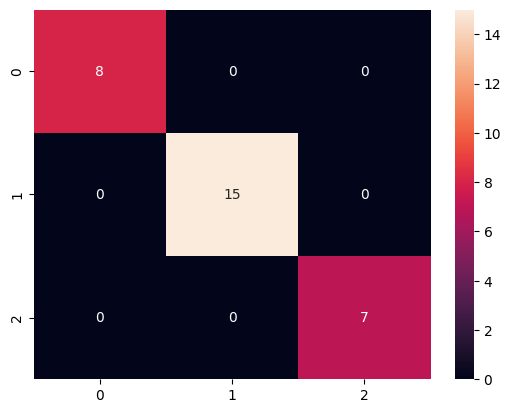

In [25]:
#Q43. Write a Python program to train an SVM Classifier and visualize the Confusion Matrix using seaborn?
#Ans.
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import confusion_matrix
X, y = load_iris(return_X_y=True)
Xt, Xts, yt, yts = train_test_split(X, y, test_size=0.2)
m = SVC().fit(Xt, yt)
sns.heatmap(confusion_matrix(yts, m.predict(Xts)), annot=True, fmt='d')
plt.show()

In [26]:
#Q44. Write a Python program to train an SVM Regressor (SVR) and evaluate its performance using Mean Absolute Error (MAE) instead of MSE?
#Ans.
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error
X, y = fetch_california_housing(return_X_y=True)
Xt, Xts, yt, yts = train_test_split(X[:500], y[:500], test_size=0.2)
m = SVR().fit(Xt, yt)
print(mean_absolute_error(yts, m.predict(Xts)))

0.7933196411863532


In [27]:
#Q45. Write a Python program to train a Naïve Bayes classifier and evaluate its performance using the ROC-AUC score?
#Ans.
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import roc_auc_score
X, y = load_breast_cancer(return_X_y=True)
Xt, Xts, yt, yts = train_test_split(X, y, test_size=0.2)
m = GaussianNB().fit(Xt, yt)
print(roc_auc_score(yts, m.predict_proba(Xts)[:, 1]))

0.9984121943474118


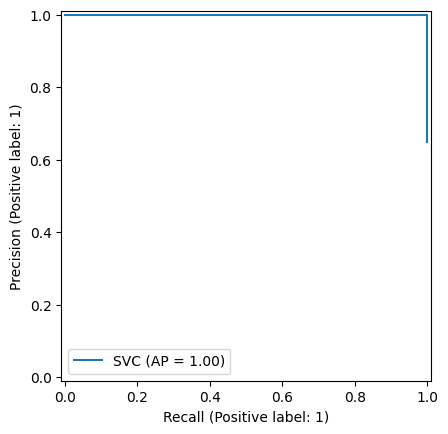

In [28]:
#Q46. Write a Python program to train an SVM Classifier and visualize the Precision-Recall Curve?
#Ans.
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import PrecisionRecallDisplay
X, y = make_classification(n_samples=100, n_classes=2, random_state=42)
Xt, Xts, yt, yts = train_test_split(X, y, test_size=0.2)
m = SVC().fit(Xt, yt)
PrecisionRecallDisplay.from_estimator(m, Xts, yts)
plt.show()